<a href="https://colab.research.google.com/github/NikitaBeker/titanic-survival-project/blob/main/notebooks/stage3_part2_preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Using Colab cache for faster access to the 'titanic-dataset' dataset.
Train размер: (80000, 28), Test размер: (20000, 28)


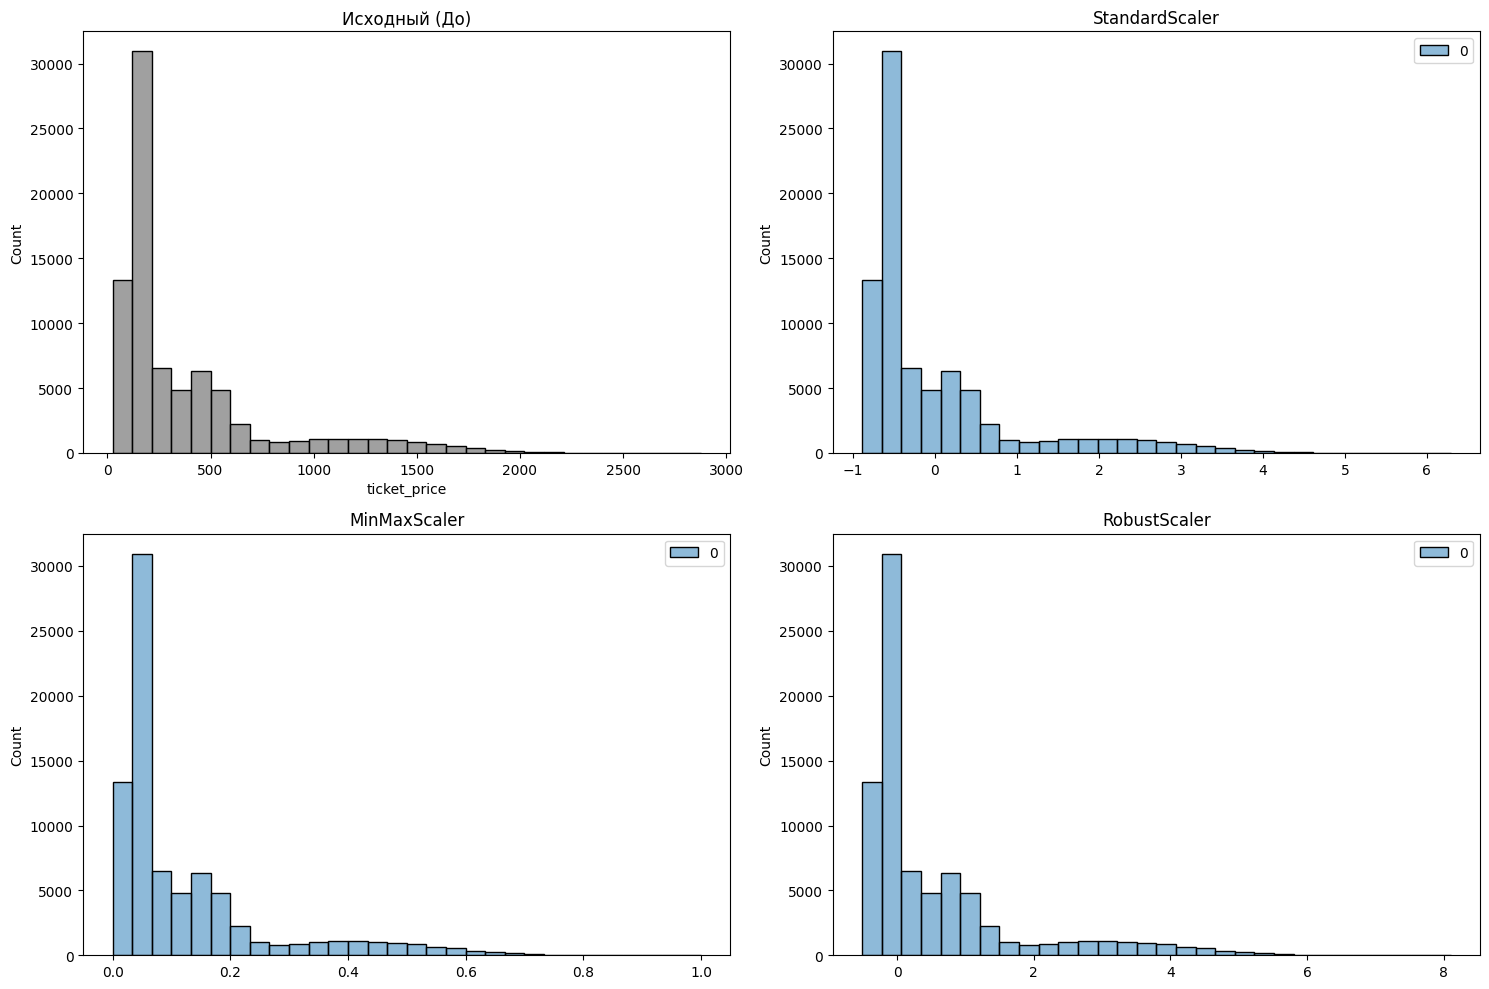

Размер обработанного Train: (80000, 61)
Размер обработанного Test: (20000, 61)


In [2]:
import kagglehub
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

path = kagglehub.dataset_download("mobeenfatimah/titanic-dataset")
csv_files = glob.glob(os.path.join(path, "*.csv"))
df = pd.read_csv(csv_files[0])
df = df.drop_duplicates()
num_cols = df.select_dtypes(include=[np.number]).columns
cat_cols = df.select_dtypes(include=['object', 'category']).columns
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])
df = df[(df['age'] > 0) & (df['age'] <= 100)]

# Разделение выборки на Train и Test (80/20)
X = df.drop(columns=['survived', 'passenger_id', 'full_name']) # Убираются ID и имена, они не нужны
y = df['survived']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Train размер: {X_train.shape}, Test размер: {X_test.shape}")

# Выбирается 1 числовой признак (ticket_price) и тестируется масштабирование
feature = 'ticket_price'

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

# До масштабирования
sns.histplot(X_train[feature], bins=30, ax=axes[0], color='gray')
axes[0].set_title('Исходный (До)')

# StandardScaler
scaler_std = StandardScaler()
std_scaled = scaler_std.fit_transform(X_train[[feature]])
sns.histplot(std_scaled, bins=30, ax=axes[1], color='blue')
axes[1].set_title('StandardScaler')

# MinMaxScaler
scaler_minmax = MinMaxScaler()
minmax_scaled = scaler_minmax.fit_transform(X_train[[feature]])
sns.histplot(minmax_scaled, bins=30, ax=axes[2], color='green')
axes[2].set_title('MinMaxScaler')

# RobustScaler
scaler_robust = RobustScaler()
robust_scaled = scaler_robust.fit_transform(X_train[[feature]])
sns.histplot(robust_scaled, bins=30, ax=axes[3], color='red')
axes[3].set_title('RobustScaler')

plt.tight_layout()
plt.show()

# Предобработка всех оставшихся столбцов
# Обоснование:
# - Категориальные признаки (gender, nationality и т.д.) закодирую через One-Hot Encoding (pd.get_dummies).
# - Числовые признаки (age, ticket_price) отмасштабируем через RobustScaler (т.к. есть выбросы).

# Числовые признаки для масштабирования
num_features = X_train.select_dtypes(include=[np.number]).columns.tolist()

# Инициализация RobustScaler для всех числовых признаков
scaler = RobustScaler()

# Обучаем scaler на train, применяю к train и test (чтобы избежать утечки данных)
X_train_num_scaled = scaler.fit_transform(X_train[num_features])
X_test_num_scaled = scaler.transform(X_test[num_features])

# Превращаем обратно в DataFrame
X_train_num_scaled = pd.DataFrame(X_train_num_scaled, columns=num_features, index=X_train.index)
X_test_num_scaled = pd.DataFrame(X_test_num_scaled, columns=num_features, index=X_test.index)

# Для категориальных признаков - One-Hot Encoding
cat_features = X_train.select_dtypes(include=['object', 'category']).columns.tolist()
X_train_cat_encoded = pd.get_dummies(X_train[cat_features], drop_first=True)
X_test_cat_encoded = pd.get_dummies(X_test[cat_features], drop_first=True)

# Выравниваю колонки (если в test не оказалось какой-то категории)
X_train_cat_encoded, X_test_cat_encoded = X_train_cat_encoded.align(X_test_cat_encoded, join='left', axis=1, fill_value=0)

# Собираю итоговые датасеты
X_train_processed = pd.concat([X_train_num_scaled, X_train_cat_encoded], axis=1)
X_test_processed = pd.concat([X_test_num_scaled, X_test_cat_encoded], axis=1)

print(f"Размер обработанного Train: {X_train_processed.shape}")
print(f"Размер обработанного Test: {X_test_processed.shape}")